In [1]:
import os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

from transformers import SegformerForSemanticSegmentation, SegformerFeatureExtractor


2025-12-18 18:13:58.557258: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766081638.808690      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766081638.891778      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1766081639.532240      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1766081639.532294      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1766081639.532298      55 computation_placer.cc:177] computation placer alr

In [2]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

student = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512",
    num_labels=1,
    ignore_mismatched_sizes=True
).to(DEVICE)

student.load_state_dict(
    torch.load(
        "/kaggle/input/student-model/pytorch/default/1/student_best_earlystop.pth",
        map_location=DEVICE
    )
)

student.eval()

feature_extractor = SegformerFeatureExtractor(
    do_resize=False,
    do_normalize=True
)

print("✅ Student model loaded")


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/15.0M [00:00<?, ?B/s]

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b0-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([1]) in the model instantiated
- decode_head.classifier.weight: found shape torch.Size([150, 256, 1, 1]) in the checkpoint and torch.Size([1, 256, 1, 1]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✅ Student model loaded


/usr/local/lib/python3.12/dist-packages/transformers/models/segformer/feature_extraction_segformer.py:30: FutureWarning: The class SegformerFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use SegformerImageProcessor instead.
  warnings.warn(


In [8]:
IMG_DIR  = "/kaggle/input/whu-building-dataset/WHU/train/Image"
MASK_DIR = "/kaggle/input/whu-building-dataset/WHU/train/Mask"

img_name = sorted(os.listdir(IMG_DIR))[5]   # pick first image

img_path  = os.path.join(IMG_DIR, img_name)
mask_path = os.path.join(MASK_DIR, img_name)

print("Testing image:", img_name)


Testing image: train_0006.png


In [9]:
IMG_SIZE = 512

# Load image
img = Image.open(img_path).convert("RGB")
img = img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
img_np = np.array(img)

# Load mask
gt = Image.open(mask_path).convert("L")
gt = gt.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)
gt = np.array(gt)
gt = (gt > 127).astype(np.uint8)

# Feature extractor
enc = feature_extractor(images=img_np, return_tensors="pt")
pixel_values = enc["pixel_values"].to(DEVICE)


In [10]:
with torch.no_grad():
    logits = student(pixel_values=pixel_values).logits
    logits = F.interpolate(
        logits,
        size=(IMG_SIZE, IMG_SIZE),
        mode="bilinear",
        align_corners=False
    )

prob_map = torch.sigmoid(logits)[0, 0].cpu().numpy()
binary_mask = (prob_map > 0.5).astype(np.uint8)


In [11]:
intersection = np.logical_and(binary_mask == 1, gt == 1).sum()
union = np.logical_or(binary_mask == 1, gt == 1).sum() + 1e-6

iou = intersection / union
print(f"📊 IoU on this image: {iou:.4f}")


📊 IoU on this image: 0.7998


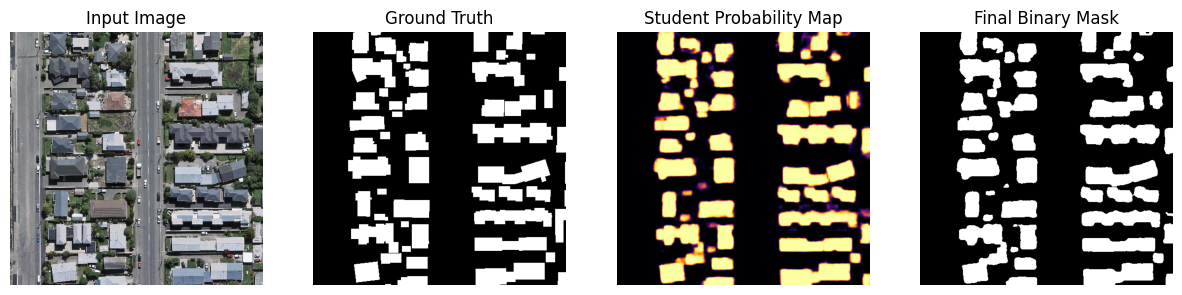

In [12]:
plt.figure(figsize=(15,4))

plt.subplot(1,4,1)
plt.imshow(img_np)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(gt, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(prob_map, cmap="inferno")
plt.title("Student Probability Map")
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(binary_mask, cmap="gray")
plt.title("Final Binary Mask")
plt.axis("off")

plt.show()
